Project 10: Overfitting and Underfitting Analysis

In [1]:
# works in Jupyter and in Google Colab
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# make results reproducible
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
iris = load_iris()
X, y = iris.data, iris.target

print("Features shape :", X.shape)
print("Labels shape   :", y.shape)
print("Class names    :", list(iris.target_names))

# ONE split, used by every model (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# scale the features (fit only on training data)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nTraining samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])

Features shape : (150, 4)
Labels shape   : (150,)
Class names    : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Training samples : 105
Testing samples  : 45


In [3]:
def train_and_evaluate(name, model, epochs=300):
    """Compile, train and score one model. Returns the numbers + history."""
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

    history = model.fit(X_train, y_train,
                        validation_data=(X_test, y_test),
                        epochs=epochs,
                        verbose=0)

    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    return {"name": name,
            "train_acc": train_acc, "test_acc": test_acc,
            "train_loss": train_loss, "test_loss": test_loss,
            "history": history}


results = []

In [4]:
model_A = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(3, activation="sigmoid"),   # no hidden layer
])

model_A.summary()
results.append(train_and_evaluate("A: too simple", model_A, epochs=15))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15 (60.00 B)

 Trainable params: 15 (60.00 B)

 Non-trainable params: 0 (0.00 B)

### Model B - one hidden layer with 16 neurons (right size)

In [5]:
model_B = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),     # 1 hidden layer
    keras.layers.Dense(3, activation="softmax"),
])

model_B.summary()
results.append(train_and_evaluate("B: right size", model_B, epochs=300))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131 (524.00 B)

 Trainable params: 131 (524.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
model_C = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(64, activation="relu"),     # hidden layer 1
    keras.layers.Dense(64, activation="relu"),     # hidden layer 2
    keras.layers.Dense(64, activation="relu"),     # hidden layer 3
    keras.layers.Dense(3, activation="softmax"),
])

model_C.summary()
results.append(train_and_evaluate("C: too complex", model_C, epochs=500))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,835 (34.51 KB)

 Trainable params: 8,835 (34.51 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
print(f"{'Model':18} {'Train Acc':>10} {'Test Acc':>10} {'Gap':>8}")
print("-" * 50)
for r in results:
    gap = r["train_acc"] - r["test_acc"]
    print(f"{r['name']:18} {r['train_acc']:10.3f} {r['test_acc']:10.3f} {gap:8.3f}")

Model               Train Acc   Test Acc      Gap
--------------------------------------------------
A: too simple           0.590      0.556    0.035
B: right size           0.971      0.911    0.060
C: too complex          1.000      0.911    0.089


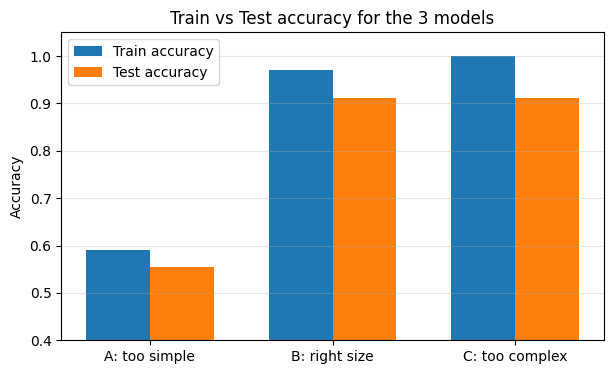

In [8]:
# bar chart: train vs test accuracy for each model
x = np.arange(len(results))
width = 0.35

plt.figure(figsize=(7, 4))
plt.bar(x - width / 2, [r["train_acc"] for r in results], width, label="Train accuracy")
plt.bar(x + width / 2, [r["test_acc"] for r in results], width, label="Test accuracy")
plt.xticks(x, [r["name"] for r in results])
plt.ylim(0.4, 1.05)
plt.ylabel("Accuracy")
plt.title("Train vs Test accuracy for the 3 models")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

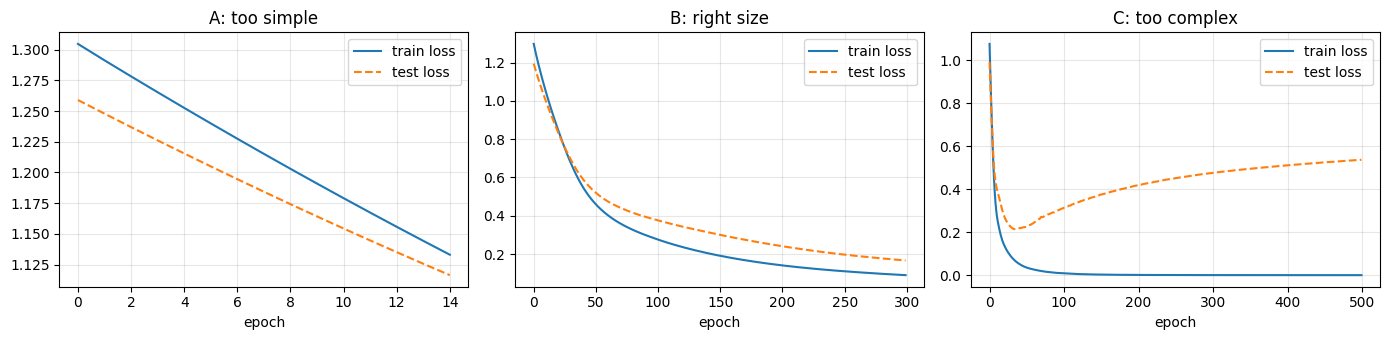

In [9]:
# learning curves: training loss (solid) vs testing loss (dashed)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, r in zip(axes, results):
    h = r["history"].history
    ax.plot(h["loss"], label="train loss")
    ax.plot(h["val_loss"], "--", label="test loss")
    ax.set_title(r["name"])
    ax.set_xlabel("epoch")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
model_fixed = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),            # <== regularisation
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),            # <== regularisation
    keras.layers.Dense(3, activation="softmax"),
])

model_fixed.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True)

history_fixed = model_fixed.fit(X_train, y_train,
                                validation_data=(X_test, y_test),
                                epochs=500, callbacks=[early_stop], verbose=0)

_, tr = model_fixed.evaluate(X_train, y_train, verbose=0)
_, te = model_fixed.evaluate(X_test, y_test, verbose=0)
print(f"Model C fixed : train acc = {tr:.3f} | test acc = {te:.3f} | gap = {tr - te:.3f}")

Model C fixed : train acc = 0.971 | test acc = 0.911 | gap = 0.060
